In [ ]:
# Внимание!!! Важно, что бы файлы с данными и исполняемый файл находились в одной папке, 
# тогда пути к тестовым и тренировочным наборам будут содержать только имена файлов.
# 
# В пути к тренировочным и тестовым данным запрежается использовать абсалютную адресацию, 
# то есть адресацию, в которой присутствуют имена папок. Путь должен содержать только имя файла.
#
# Напоминание: под моделью машинного обучения понимаются все действия с исходными данными, 
# которые необходимо произвести, что бы сопоставить признаки целевому значению.

### Область работы 1 (библиотеки)

In [ ]:
# Данный блок в области 1 НЕ выполняется преподавателем
# 
# данный блок предназначен только для подключения необходимых библиотек
# запрещается подключать библиотеки в других блоках
#
# установка дополнительных библиотек размещается прямо здесь (обязательно закоментированы)
#
# pip install

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import pandas.plotting as pd_plt
import matplotlib.colors as plt_colors
from IPython.display import display, display_html

from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn import svm
from sklearn.svm import SVC

from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler, Normalizer, FunctionTransformer
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, KFold, StratifiedShuffleSplit, StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay, roc_curve, roc_auc_score
from sklearn.metrics import precision_score, recall_score, make_scorer, f1_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder,LabelEncoder, OneHotEncoder, TargetEncoder
from sklearn.compose import ColumnTransformer, make_column_transformer
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import validation_curve


### Область работы 2 (поиск  модели .... )

In [2]:
# Данный блок(и) НЕ выполняются преподавателем в области 2
# блок(и) предназначены для поиска лучшей модели 
# должен быть понятен и очевиден отбор параметров модели
# 
# Запрещается размещать данные блоки за пределами обасти 2
# Все блоки данной области должны быть выполнены
#
# ЗАПРЕЩАЕТСЯ ИСПОЛЬЗОВАТЬ ТЕСТОВЫЙ НАБОР
#
# Путь к тренировочному набору
# 

path_train = 'train.csv' # содержит только имя файла, без имен папок !!!

In [3]:
df = pd.read_csv(path_train)

In [4]:
display(df.head(3))

,bill_depth_mm,bill_length_mm,body_mass_g,flipper_length_mm,island,sex,year,species
0,13.6,44.0,4350,208.0,Biscoe,female,2008,Gentoo
1,19.4,45.6,3525,194.0,Dream,female,2009,Chinstrap
2,18.8,52.2,3450,NaN,Dream,male,2009,Chinstrap


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 261 entries, 0 to 260
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   bill_depth_mm      260 non-null    float64
 1   bill_length_mm     258 non-null    float64
 2   body_mass_g        261 non-null    int64  
 3   flipper_length_mm  256 non-null    float64
 4   island             261 non-null    object 
 5   sex                256 non-null    object 
 6   year               261 non-null    int64  
 7   species            261 non-null    object 
dtypes: float64(3), int64(2), object(3)
memory usage: 16.4+ KB


In [6]:
df.describe()

,bill_depth_mm,bill_length_mm,body_mass_g,flipper_length_mm,year
count,260.000000,258.000000,261.000000,256.000000,261.00000
mean,17.227692,43.798837,4190.517241,200.464844,2008.05364
std,2.016822,5.327233,786.159494,13.968267,0.80682
min,13.200000,32.100000,2850.000000,172.000000,2007.00000
25%,15.600000,39.350000,3550.000000,190.000000,2007.00000
50%,17.300000,44.450000,4050.000000,196.000000,2008.00000
75%,18.800000,47.600000,4750.000000,213.000000,2009.00000
max,21.500000,59.600000,6300.000000,230.000000,2009.00000


In [9]:
display(df[df.isna().any(axis=1)]) #строки с NA

,bill_depth_mm,bill_length_mm,body_mass_g,flipper_length_mm,island,sex,year,species
2,18.8,52.2,3450,NaN,Dream,male,2009,Chinstrap
6,13.8,47.3,4725,216.0,Biscoe,NaN,2009,Gentoo
54,21.1,34.6,4400,NaN,Torgersen,male,2007,Adelie
55,17.2,NaN,3550,196.0,Torgersen,female,2008,Adelie
62,14.4,46.2,4650,214.0,Biscoe,NaN,2008,Gentoo
113,18.1,34.1,3475,193.0,Torgersen,NaN,2007,Adelie
123,NaN,37.2,3900,184.0,Torgersen,NaN,2008,Adelie
161,20.2,42.0,4250,190.0,Torgersen,NaN,2007,Adelie
163,20.7,NaN,4500,197.0,Torgersen,male,2007,Adelie
169,13.9,NaN,4400,214.0,Biscoe,female,2008,Gentoo


In [10]:
df.isna().sum()

bill_depth_mm        1
bill_length_mm       3
body_mass_g          0
flipper_length_mm    5
island               0
sex                  5
year                 0
species              0
dtype: int64

In [11]:
print('количество строк дубликатов:', df.duplicated().sum())
df = df.drop_duplicates() #удалим

количество строк дубликатов: 7


In [12]:
df['species'].value_counts()

species
Adelie       114
Gentoo        89
Chinstrap     51
Name: count, dtype: int64

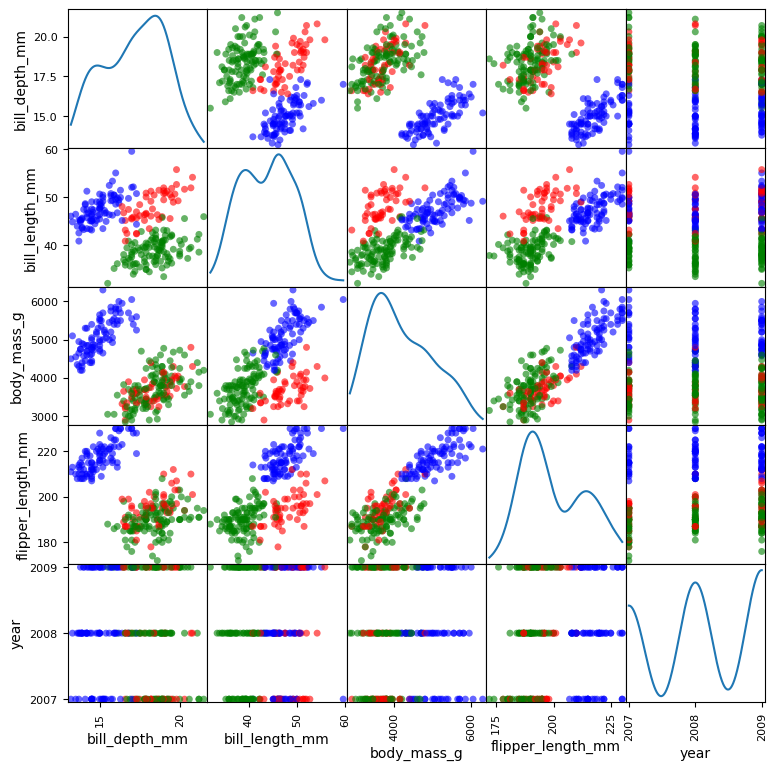

In [25]:
#рисуем, как целевая переменная располагается в зависимости от разных признаков
df_n=df.dropna()
pd_plt.scatter_matrix(df_n,   
                     c=pd.factorize(df_n['species'])[0], 
                     alpha=0.6, 
                     s=100, 
                     figsize=(9, 9), 
                     diagonal='kde',  
                     cmap=plt_colors.ListedColormap(['blue','red', 'green'])
                    )
plt.show()

In [15]:
X = df.drop(['species'], axis=1)
y = df.species.map({'Adelie':0, 'Gentoo':1, 'Chinstrap':2}) #переобазначили целевую

In [16]:
#разделили
X_train, X_test, y_train, y_test = train_test_split( X, y, train_size=0.75, 
                                                    test_size=0.25, stratify=y)
X_train.head(3)

,bill_depth_mm,bill_length_mm,body_mass_g,flipper_length_mm,island,sex,year
114,18.3,47.6,3850,195.0,Dream,female,2008
92,15.1,48.1,5500,209.0,Biscoe,male,2009
161,20.2,42.0,4250,190.0,Torgersen,NaN,2007


In [17]:
cat_features = ["island", "sex", "year"] # если year в категориальные
num_features = ["bill_depth_mm", "bill_length_mm", 'body_mass_g','flipper_length_mm']  

In [18]:
#это для числовых признаков num_features
num = Pipeline(steps=[
    ('missing_num', SimpleImputer(strategy='median')),  #заполняем NA медианой
    ('poly', PolynomialFeatures(degree=3)), 
    ('scaler', StandardScaler()) 
])

#это для категориальных признаков cat_features
cat = Pipeline(steps=[
    ('missing_num', SimpleImputer(strategy='most_frequent')), #заполняем NA наиболее часто встречающимся значением 
    ('onehot', OneHotEncoder(sparse_output=False)) 
    
    ])

   
CT = ColumnTransformer([
        ("num", num, num_features), 
        ("cat", cat, cat_features)
        ]).set_output(transform='pandas')

display(CT)

ct = CT.fit_transform(X_train)
pd.DataFrame(ct).head()

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('missing_num',
                                                  SimpleImputer(strategy='median')),
                                                 ('poly',
                                                  PolynomialFeatures(degree=3)),
                                                 ('scaler', StandardScaler())]),
                                 ['bill_depth_mm', 'bill_length_mm',
                                  'body_mass_g', 'flipper_length_mm']),
                                ('cat',
                                 Pipeline(steps=[('missing_num',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(sparse_output=False))]),
                                 ['island', 'sex', 'year'])])

,num__1,num__bill_depth_mm,num__bill_length_mm,num__body_mass_g,num__flipper_length_mm,num__bill_depth_mm^2,num__bill_depth_mm bill_length_mm,num__bill_depth_mm body_mass_g,num__bill_depth_mm flipper_length_mm,num__bill_length_mm^2,...,num__body_mass_g flipper_length_mm^2,num__flipper_length_mm^3,cat__island_Biscoe,cat__island_Dream,cat__island_Torgersen,cat__sex_female,cat__sex_male,cat__year_2007,cat__year_2008,cat__year_2009
114,0.0,0.566758,0.707327,-0.458708,-0.423706,0.530641,1.076306,-0.120749,0.391642,0.671437,...,-0.501242,-0.464176,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
92,0.0,-1.078058,0.801703,1.555368,0.585299,-1.073490,-0.227766,0.889117,-0.861920,0.773548,...,1.122579,0.520381,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
161,0.0,1.543368,-0.349690,0.029553,-0.784066,1.628528,0.872007,1.113621,1.210436,-0.399316,...,-0.379628,-0.783397,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0
24,0.0,-0.512652,1.065957,1.921564,2.026736,-0.556740,0.453140,1.763880,0.820939,1.065137,...,2.228418,2.174080,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
100,0.0,-0.975257,0.650701,1.250205,1.522233,-0.982237,-0.251366,0.670627,-0.130625,0.610682,...,1.442597,1.560795,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0


In [21]:
pipe = Pipeline(steps=[
    ('preprocessor', CT),
    ('classifier', LogisticRegression(max_iter=10000))
    ])


cv = StratifiedShuffleSplit(test_size = .25, train_size = .75, n_splits = 5)

param_grid = [{'classifier__penalty': ['l2'], 
     'classifier__solver': ['newton-cg', 'lbfgs', 'liblinear', 'sag', 'saga']},   
    
    {'classifier__penalty': ['l1'], 'classifier__solver': ['liblinear']},  
    
    {'classifier__penalty': [None], 
     'classifier__solver': ['lbfgs', 'newton-cg']}]



grid = GridSearchCV(pipe, param_grid, cv = cv, return_train_score = True)
grid.fit(X_train, y_train)

print("Наилучшие параметры:\n{}\n".format(grid.best_params_))
print("Средняя правильность для наилучшей модели кроссвалидации на \
                валидационных тестовых наборах: {:.6f}\n".format(grid.best_score_)) 
print("Правильность для наилучшей модели на тестовом наборе: {:.6f}\n".format(grid.score(X_test, y_test)))

   
grid_result = pd.DataFrame(grid.cv_results_).sort_values(["rank_test_score",'std_test_score']).T
grid_result

Наилучшие параметры:
{'classifier__penalty': 'l2', 'classifier__solver': 'newton-cg'}

Средняя правильность для наилучшей модели кроссвалидации на                 валидационных тестовых наборах: 0.987500

Правильность для наилучшей модели на тестовом наборе: 0.984375



,0,1,3,4,2,5,7,6
mean_fit_time,0.010701,0.006706,0.021789,0.034051,0.005814,0.005693,0.005815,0.005053
std_fit_time,0.00941,0.002277,0.002286,0.012326,0.001833,0.000271,0.000163,0.000093
mean_score_time,0.003005,0.00263,0.002699,0.002796,0.00264,0.002516,0.002604,0.002607
std_score_time,0.000478,0.000115,0.00014,0.000269,0.000118,0.000017,0.000026,0.000083
param_classifier__penalty,l2,l2,l2,l2,l2,l1,None,None
param_classifier__solver,newton-cg,lbfgs,sag,saga,liblinear,liblinear,newton-cg,lbfgs
params,"{'classifier__penalty': 'l2', 'classifier__sol...","{'classifier__penalty': 'l2', 'classifier__sol...","{'classifier__penalty': 'l2', 'classifier__sol...","{'classifier__penalty': 'l2', 'classifier__sol...","{'classifier__penalty': 'l2', 'classifier__sol...","{'classifier__penalty': 'l1', 'classifier__sol...","{'classifier__penalty': None, 'classifier__sol...","{'classifier__penalty': None, 'classifier__sol..."
split0_test_score,1.0,1.0,1.0,1.0,0.979167,0.979167,0.979167,0.979167
split1_test_score,0.979167,0.979167,0.979167,0.979167,0.979167,0.979167,0.979167,0.979167
split2_test_score,0.958333,0.958333,0.958333,0.958333,0.958333,0.958333,0.958333,0.979167


Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('missing_num',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('poly',
                                                                   PolynomialFeatures(degree=3)),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['bill_depth_mm',
                                                   'bill_length_mm',
                                                   'body_mass_g',
                                                   'flipper_length_mm']),
                                                 ('cat',
                                                 

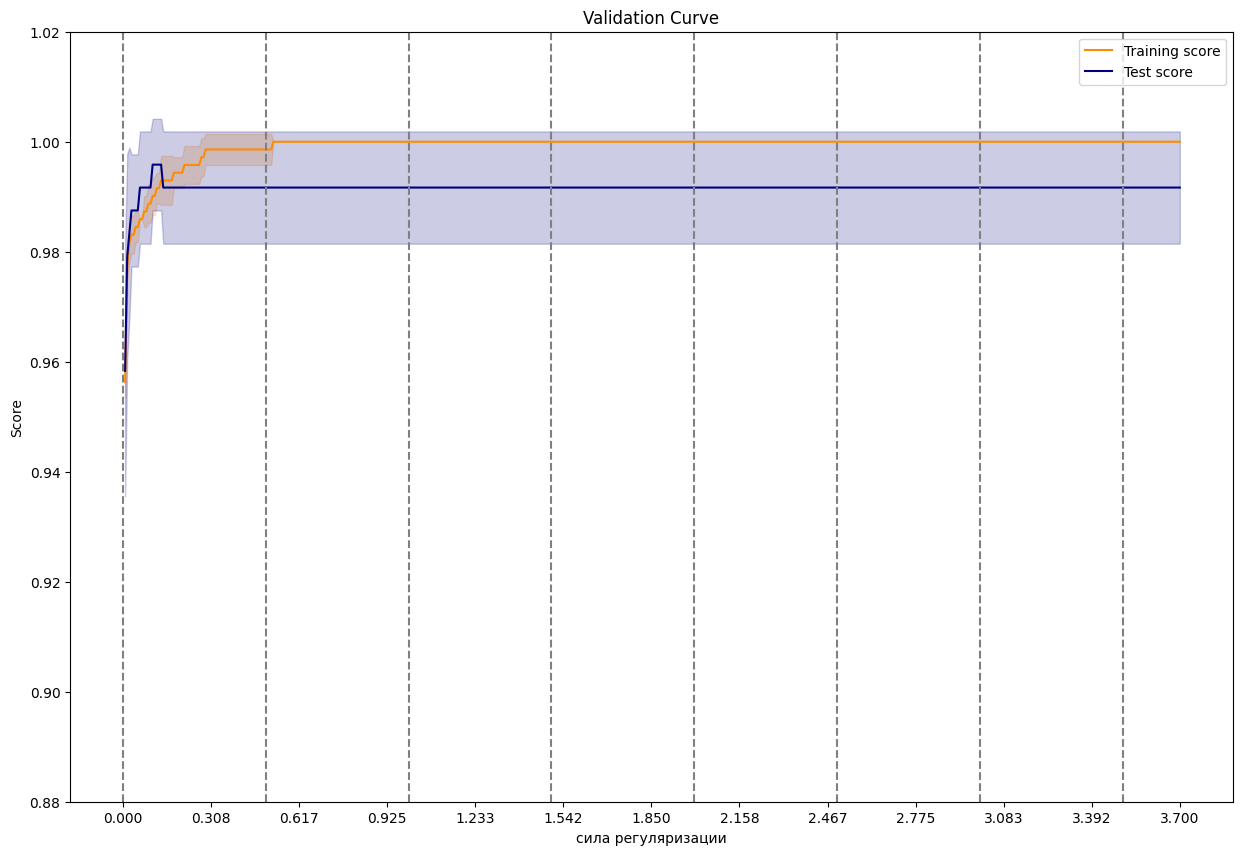

In [45]:
pipe_fin = make_pipeline(CT, LogisticRegression(solver = 'newton-cg', penalty = 'l2'))
print(pipe_fin)

n_range = np.linspace(0, 3.7, 500)
train_scores, test_scores = validation_curve(
    pipe_fin , X_train, y_train,
    param_name = "logisticregression__C", 
    param_range = n_range,
    cv = cv, 
    scoring='accuracy', 
    n_jobs=-1)

train_scores_mean = np.mean(train_scores, axis=1)
train_scores_std = np.std(train_scores, axis=1)
test_scores_mean = np.mean(test_scores, axis=1)
test_scores_std = np.std(test_scores, axis=1)

plt.figure(figsize=(15,10))

plt.title("Validation Curve")
plt.xlabel("сила регуляризации")
plt.ylabel("Score")
plt.ylim(0.88, 1.02)

plt.plot(n_range, train_scores_mean, label="Training score", color="darkorange")
plt.fill_between(n_range, train_scores_mean - train_scores_std,
                 train_scores_mean + train_scores_std, alpha=0.2,
                 color="darkorange")
plt.plot(n_range, test_scores_mean, label="Test score",
             color="navy")
plt.fill_between(n_range, test_scores_mean - test_scores_std,
                 test_scores_mean + test_scores_std, alpha=0.2,
                 color="navy")

plt.xticks(np.linspace(0, 3.7, 13))
for i in np.arange(0,3.7,0.5):
    plt.vlines(i, 0.88,1.05, linestyles='dashed', colors='gray')

plt.legend(loc="best")
plt.show();

In [46]:
model_log = make_pipeline(CT, LogisticRegression(solver = 'newton-cg', 
                                                 penalty = 'l2', C=1, max_iter=3000))
model_log.fit(X_train,y_train)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('missing_num',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('poly',
                                                                   PolynomialFeatures(degree=3)),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['bill_depth_mm',
                                                   'bill_length_mm',
                                                   'body_mass_g',
                                                   'flipper_length_mm']),
                                                 ('cat',
                                                  Pipeline(steps=[('missing_num',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(sparse_output=False))]),
                                                  ['island', 'sex', 'year'])])),
                ('logisticregression',
                 LogisticRegression(C=1, max_iter=3000, solver='newton-cg'))])

In [47]:
# предсказываем значения 
y_pred_log = model_log.predict(X_test)
print(classification_report(y_test, y_pred_log))

              precision    recall  f1-score   support

           0       1.00      0.97      0.98        29
           1       1.00      1.00      1.00        22
           2       0.93      1.00      0.96        13

    accuracy                           0.98        64
   macro avg       0.98      0.99      0.98        64
weighted avg       0.99      0.98      0.98        64



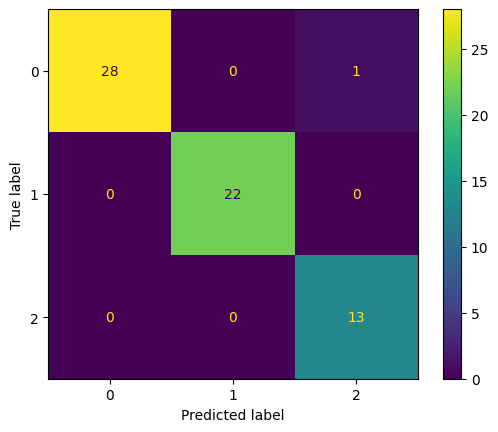

In [48]:
matrix=confusion_matrix(y_test,y_pred_log)
ConfusionMatrixDisplay(matrix).plot()
plt.show()